# code_087 · Decision trees and recursive partitioning

**Book:** section 18.1. A self-contained trees-and-ensembles laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_18_GUIDE.md), [run evidence](../CHAPTER_18_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_087).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=1887;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 1887


<a id="path"></a>
## Supplement the preserved code_001 laboratory

The [original tree notebook](001_Chapter_18_01_Decision_Tree.ipynb) retains its published byte-for-byte source/outputs and covers all constructor controls, pruning and a separate final assessment. This independent supplement generates320training and200final records: near-duplicate load descriptors plus resistance, Bernoulli risk sigmoid(-2+3*load-2*resistance). Fit a depth2/minleaf12 tree for a readable path, not a tuned claim. Trace a fixed synthetic query[.7,.7,.3] to its actual training leaf, verifying weighted child impurity and leaf proportions. Forty fixed perturbations flip eight training labels each; report early-split variation without picking the most attractive result. These labels are a construction, not structural safety evidence.


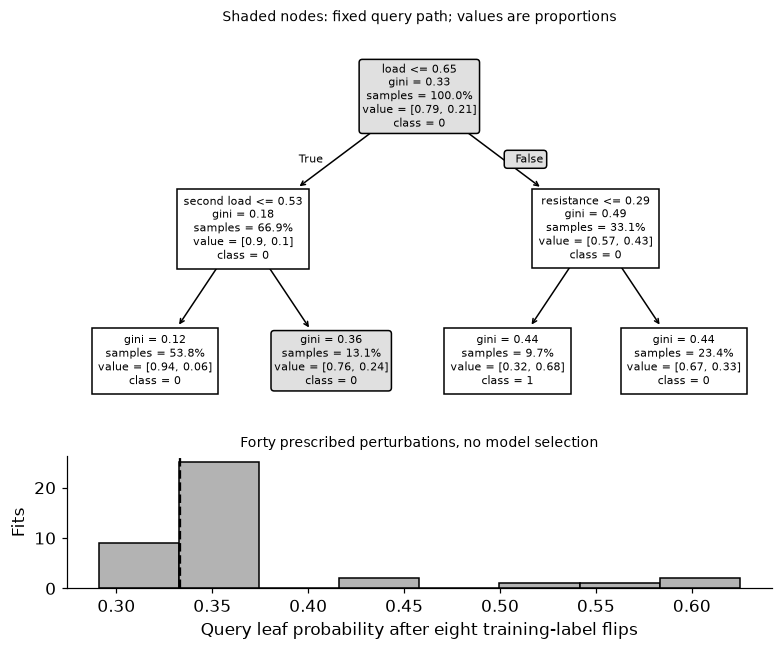

In [2]:
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.metrics import brier_score_loss
from scipy.special import expit
load=rng.uniform(0,1,320);resistance=rng.uniform(0,1,320);X=np.column_stack([load,load+rng.normal(0,.025,320),resistance]);y=rng.binomial(1,expit(-2+3*load-2*resistance));tl=rng.uniform(0,1,200);tr=rng.uniform(0,1,200);Xt=np.column_stack([tl,tl+rng.normal(0,.025,200),tr]);yt=rng.binomial(1,expit(-2+3*tl-2*tr));model=DecisionTreeClassifier(max_depth=2,min_samples_leaf=12,random_state=SEED).fit(X,y);query=np.array([[.7,.7,.3]]);nodes=model.decision_path(query).indices;leaf=int(model.apply(query)[0]);assert nodes[-1]==leaf;assert model.tree_.children_left[leaf]==-1
members=model.apply(X)==leaf;p=float(y[members].mean());np.testing.assert_allclose(model.predict_proba(query)[0,1],p);root=model.tree_;left,right=root.children_left[0],root.children_right[0];gain=float(root.impurity[0]-(root.weighted_n_node_samples[left]*root.impurity[left]+root.weighted_n_node_samples[right]*root.impurity[right])/root.weighted_n_node_samples[0]);assert gain>=0
paths=[{'node':int(j),'feature':int(root.feature[j]),'threshold':float(root.threshold[j])} for j in nodes if root.children_left[j]!=-1];perturb=[]
for _ in range(40):
 changed=y.copy();ix=rng.choice(len(y),8,replace=False);changed[ix]=1-changed[ix];fit=DecisionTreeClassifier(max_depth=2,min_samples_leaf=12,random_state=SEED).fit(X,changed);perturb.append({'root_feature':int(fit.tree_.feature[0]),'root_threshold':float(fit.tree_.threshold[0]),'query_probability':float(fit.predict_proba(query)[0,1])})
RESULTS['tree']={'training':320,'final':200,'query':query[0].tolist(),'path':paths,'leaf':leaf,'leaf_records':int(members.sum()),'leaf_class1_fraction':p,'root_impurity_decrease':gain,'final_brier':float(brier_score_loss(yt,model.predict_proba(Xt)[:,1]))};RESULTS['perturbations']={'runs':40,'labels_flipped_per_run':8,'root_features':np.bincount([r['root_feature'] for r in perturb],minlength=3).tolist(),'query_probability_min':min(r['query_probability'] for r in perturb),'query_probability_max':max(r['query_probability'] for r in perturb),'root_threshold_min':min(r['root_threshold'] for r in perturb),'root_threshold_max':max(r['root_threshold'] for r in perturb)}
fig,axes=plt.subplots(2,1,figsize=(7,5.8),height_ratios=[3,1]);artists=plot_tree(model,feature_names=['load','second load','resistance'],class_names=['0','1'],proportion=True,precision=2,filled=False,ax=axes[0],fontsize=7)
for node in nodes:artists[node].set_bbox(dict(boxstyle='round',facecolor='.88',edgecolor='black'))
axes[0].set_title('Shaded nodes: fixed query path; values are proportions');axes[1].hist([r['query_probability'] for r in perturb],bins=8,color='.7',edgecolor='black');axes[1].axvline(p,color='black',ls='--');axes[1].set(xlabel='Query leaf probability after eight training-label flips',ylabel='Fits',title='Forty prescribed perturbations, no model selection');plt.show()


<a id="missing"></a>
## Missing is a fitted route; an unseen category is a contract choice

A separate tiny missing-numeric fixture trains a depth1 tree and verifies finite probability predictions and consistent application. Inspect missing_go_to_left in the pinned fitted tree to report the learned missing branch; this private storage field is version-specific and not a portable preprocessing API. A training-only one-hot material encoder ignores unknown categories by its declared policy: steel/concrete/timber produce learned indicators, while unseen polymer yields an all-zero block. An unknown category and a missing numeric value are different representations. This audit does not claim native categorical splitting in DecisionTreeClassifier or an optimal unknown-category policy.


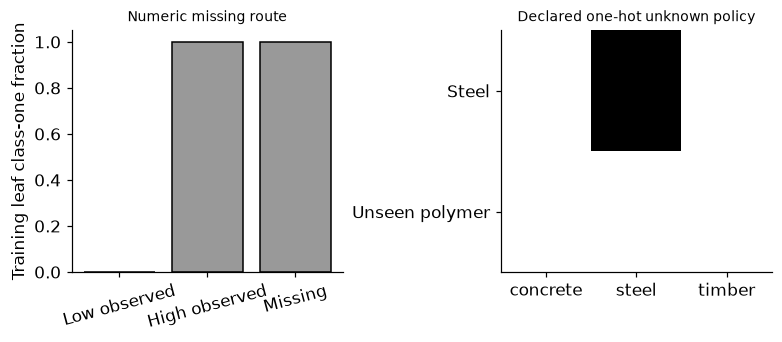

In [3]:
from sklearn.preprocessing import OneHotEncoder
mx=np.array([[0.],[.1],[.2],[.8],[.9],[1.],[np.nan],[np.nan]]);my=np.array([0,0,0,1,1,1,1,1]);route=DecisionTreeClassifier(max_depth=1,random_state=SEED).fit(mx,my);nan_leaf=int(route.apply([[np.nan]])[0]);missing_left=bool(route.tree_.missing_go_to_left[0]);expected=int(route.tree_.children_left[0] if missing_left else route.tree_.children_right[0]);assert nan_leaf==expected;assert np.isfinite(route.predict_proba([[np.nan]])).all()
enc=OneHotEncoder(handle_unknown='ignore',sparse_output=False).fit(np.array(['steel','concrete','timber'])[:,None]);encoded=enc.transform(np.array(['steel','polymer'])[:,None]);assert encoded[0].sum()==1 and encoded[1].sum()==0
RESULTS['observation_contract']={'missing_numeric_leaf':nan_leaf,'root_missing_goes_left':missing_left,'missing_probability':float(route.predict_proba([[np.nan]])[0,1]),'onehot_training_categories':enc.categories_[0].tolist(),'unknown_category_block':encoded[1].tolist(),'native_categorical_tree_claimed':False}
fig,axes=plt.subplots(1,2,figsize=(7,3));axes[0].bar(['Low observed','High observed','Missing'],route.predict_proba([[.1],[.9],[np.nan]])[:,1],color='.6',edgecolor='black');axes[0].set(ylabel='Training leaf class-one fraction',ylim=(0,1.05),title='Numeric missing route');axes[0].tick_params(axis='x',labelrotation=15);axes[1].imshow(encoded,cmap='Greys',vmin=0,vmax=1,aspect='auto');axes[1].set(xticks=range(3),xticklabels=enc.categories_[0],yticks=[0,1],yticklabels=['Steel','Unseen polymer'],title='Declared one-hot unknown policy');plt.show()


In [4]:
summary={'example_id':'code_087','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['weighted impurity and actual decision paths', 'small label perturbation and root instability', 'missing routes versus unknown categories', 'linked original tree-control laboratory'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["weighted impurity and actual decision paths", "small label perturbation and root instability", "missing routes versus unknown categories", "linked original tree-control laboratory"], "elapsed_seconds": 0.421, "example_id": "code_087", "hardware": "Darwin arm64 CPU", "results": {"observation_contract": {"missing_numeric_leaf": 2, "missing_probability": 1.0, "native_categorical_tree_claimed": false, "onehot_training_categories": ["concrete", "steel", "timber"], "root_missing_goes_left": false, "unknown_category_block": [0.0, 0.0, 0.0]}, "perturbations": {"labels_flipped_per_run": 8, "query_probability_max": 0.625, "query_probability_min": 0.2909090909090909, "root_features": [24, 16, 0], "root_threshold_max": 0.6547884047031403, "root_threshold_min": 0.49774351716041565, "runs": 40}, "tree": {"final": 200, "final_brier": 0.170150590021329, "leaf": 6, "leaf_class1_fraction": 0.3333333333333333, "leaf_records": 75, "path": [{"feature": 0, 